# Chunk length distributions

How does each method divide the selected rows into contiguous chunks?
Compare all traces at a requested budget, with one panel per method.
Read the saved results from [02_02](02_02_global_oracle.ipynb) and
[02_03](02_03_selector_sweep.ipynb), generated from the same experiment.

This notebook runs independently of [02_04](02_04_analyze_oracle.ipynb),
which shows retained importance versus modeled latency.
Paper's actual chunks are included even when it selects fewer than the requested rows.
Display figures inline only.

In [1]:
import json
from math import ceil

import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt

## 1. Data

Intervals are maximal selected runs, stored as `[start, end)` pairs.
Their length is `end - start` rows. Adjacent selected tiles have already been
merged, so a chunk's length can differ from the method's tile width.
Use the original requested fractions as keys: `0.1` means 10%.

In [2]:
reference = pd.read_csv("oracle_reference.csv", float_precision="round_trip")
selectors = pd.read_csv("selector_results.csv", float_precision="round_trip")

# Combine the recorded methods.
results = pd.concat([reference, selectors], ignore_index=True)
results["intervals"] = results.intervals.map(json.loads)

In [3]:
# One record per trace, method, and requested budget within each shape.
assert not results.duplicated(["n", "d", "method", "fraction", "trace_id"]).any()

## 2. Chunks

`chunks[shape]` is a `ShapeResults` object:

- `shape`, `saturation_rows`, `trace_count`: metadata for this shape.
- `methods`: `MethodResults` objects, ordered by decreasing tile width after the baselines.

`chunks[shape].methods[method]` keeps the method's `tile_width` and its `budgets`.
Each budget is a `ChunkLengths` object:

- `lengths`: all recorded chunk lengths in rows.
- `trace_ids`, `trace_count`: the traces contributing to this budget, including empty masks.
- `histogram(bins)`: the mean number of chunks per trace in each bin.

For each bin, sum its chunk counts across traces and divide by the number of traces.
The histogram heights therefore sum to the mean number of chunks per trace.
They are counts, not percentages or probability densities; traces with more chunks
contribute more chunks. Empty masks contribute zero counts and remain in the denominator.

In [4]:
class ChunkLengths:
    def __init__(self, rows):
        self.trace_ids   = pd.Index(rows.trace_id).sort_values()
        self.trace_count = len(self.trace_ids)

        lengths = []

        for intervals in rows.intervals:
            for start, end in intervals:
                lengths.append(end - start)

        self.lengths = np.asarray(lengths, dtype=int)

    def histogram(self, bins):
        counts, edges = np.histogram(self.lengths, bins=bins)
        return counts / self.trace_count

In [5]:
class MethodResults:
    def __init__(self, rows):
        self.tile_width = rows.tile_width.iloc[0]
        self.budgets    = {}

        for fraction, group in rows.groupby("fraction"):
            self.budgets[fraction] = ChunkLengths(group)

    def assert_comparable_to(self, baseline):
        assert self.budgets.keys() == baseline.budgets.keys()

        for fraction, group in self.budgets.items():
            current_index  = group.trace_ids
            baseline_index = baseline.budgets[fraction].trace_ids

            assert current_index.equals(baseline_index)

In [6]:
class ShapeResults:
    def __init__(self, shape, rows):
        self.shape           = shape
        self.saturation_rows = rows.saturation_rows.iloc[0]
        self.trace_count     = rows.trace_id.nunique()
        self.methods         = {}

        groups = rows.groupby("method")

        widths = groups.tile_width.first()
        widths = widths.sort_values(
            ascending   = False,
            na_position = "first",
        )

        for name in widths.index:
            method_rows = groups.get_group(name)
            self.methods[name] = MethodResults(method_rows)

In [7]:
chunks = {}

for shape, rows in results.groupby(["n", "d"]):
    chunks[shape] = ShapeResults(shape, rows)

In [8]:
chunks[(896, 896)].methods["Global DP"].budgets[0.1].lengths[:10]

array([89, 89, 89, 89, 89, 89, 89, 89, 89, 89])

In [9]:
# Check matching fractions and trace IDs across methods.
for result in chunks.values():
    baseline = result.methods["Global DP"]

    for method in result.methods.values():
        method.assert_comparable_to(baseline)

## 3. Plot

Choose a recorded `FRACTION` below. All shapes and budgets are prepared above;
changing the displayed budget only requires rerunning the final two cells.
Each shape gets one figure, with one histogram per method in the same order as 02_04.

All panels in a figure share bins and axis ranges. Bin edges start from 32 intervals
spaced on a log scale, are rounded to half-integer boundaries, and are deduplicated.
They cover lengths from 1 through `n` and stay fixed across budgets for that shape.
Longer-length bins span more row lengths; each height counts all chunks in that bin.
The x axis is logarithmic. The shared y axis is linear up to one chunk per trace
and logarithmic above, keeping zeros and low counts visible alongside fragmented methods.

The dashed line marks the model's saturation boundary `s` in rows.
Color identifies the requested fraction, using the same scale as 02_04.
Actual selected row counts can differ at the same requested budget.

In [10]:
color_scale = plt.cm.ScalarMappable(
    norm = plt.Normalize(results.fraction.min(), results.fraction.max()),
    cmap = "viridis",
)

In [11]:
def create_panels(count, ncols=4):
    nrows = ceil(count / ncols)

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize = (4 * ncols, 3 * nrows),
        sharex  = True,
        sharey  = True,
        squeeze = False,
        layout  = "constrained",
    )

    axes = axes.flatten()

    for ax in axes[count:]:
        fig.delaxes(ax)

    return fig, axes[:count]

In [12]:
def draw_method(ax, method, fraction, bins):
    group  = method.budgets[fraction]
    counts = group.histogram(bins)

    ax.stairs(
        counts, bins,
        color     = color_scale.to_rgba(fraction),
        fill      = True,
        alpha     = 0.8,
        linewidth = 0.8,
    )

In [13]:
def draw_shape(result, fraction):
    n, d    = result.shape
    s       = result.saturation_rows
    methods = result.methods

    # Shared bins for integer chunk lengths.
    bins = np.geomspace(1, n + 1, 33)
    bins = np.unique(bins.round()) - 0.5

    fig, axes = create_panels(len(methods))

    for ax, (name, method) in zip(axes, methods.items()):
        draw_method(ax, method, fraction, bins)

        ax.axvline(
            s,
            color     = "gray",
            linestyle = "--",
            linewidth = 1.2,
        )

        title = name
        if pd.notna(method.tile_width):
            title += f"\nB = {method.tile_width:g}"

        ax.set(
            title  = title,
            xscale = "log",
            xlim   = (bins[0], bins[-1]),
        )
        ax.set_yscale("symlog", linthresh=1)

    # Include every method before fixing the shared lower limit.
    axes[0].set_ylim(bottom=0)

    fig.supxlabel("Chunk length (rows)")
    fig.supylabel("Mean chunks per trace per bin")

    title = f"{n} x {d} · {fraction:.0%} requested · {result.trace_count} traces"
    subtitle = f"Dashed line: s = {s:.2f} rows · Shared bins and axes"
    scale = "Y axis: linear up to 1 chunk per trace, logarithmic above"
    fig.suptitle(f"{title}\n{subtitle}\n{scale}")
    return fig

In [14]:
FRACTION = 0.5

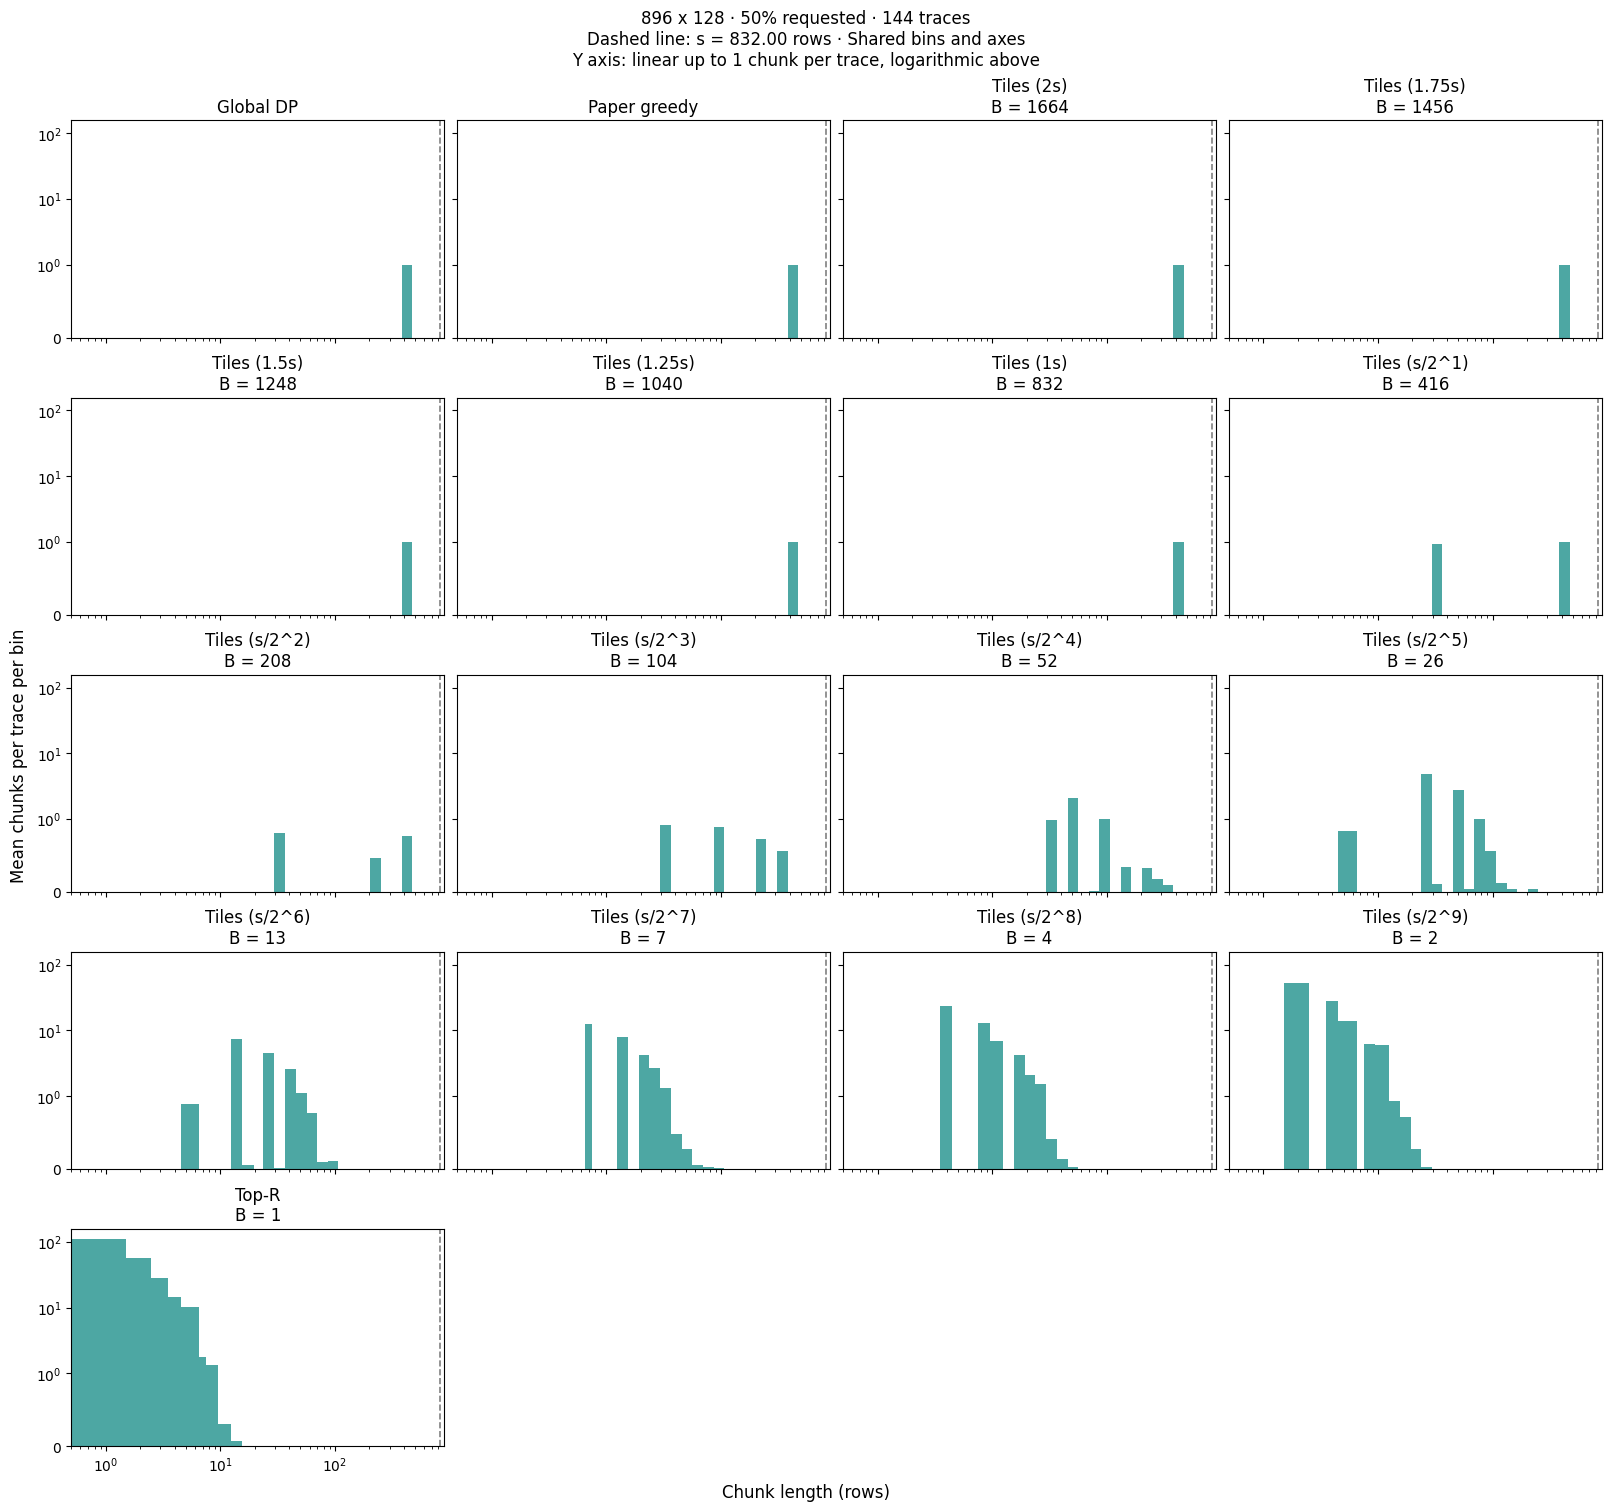

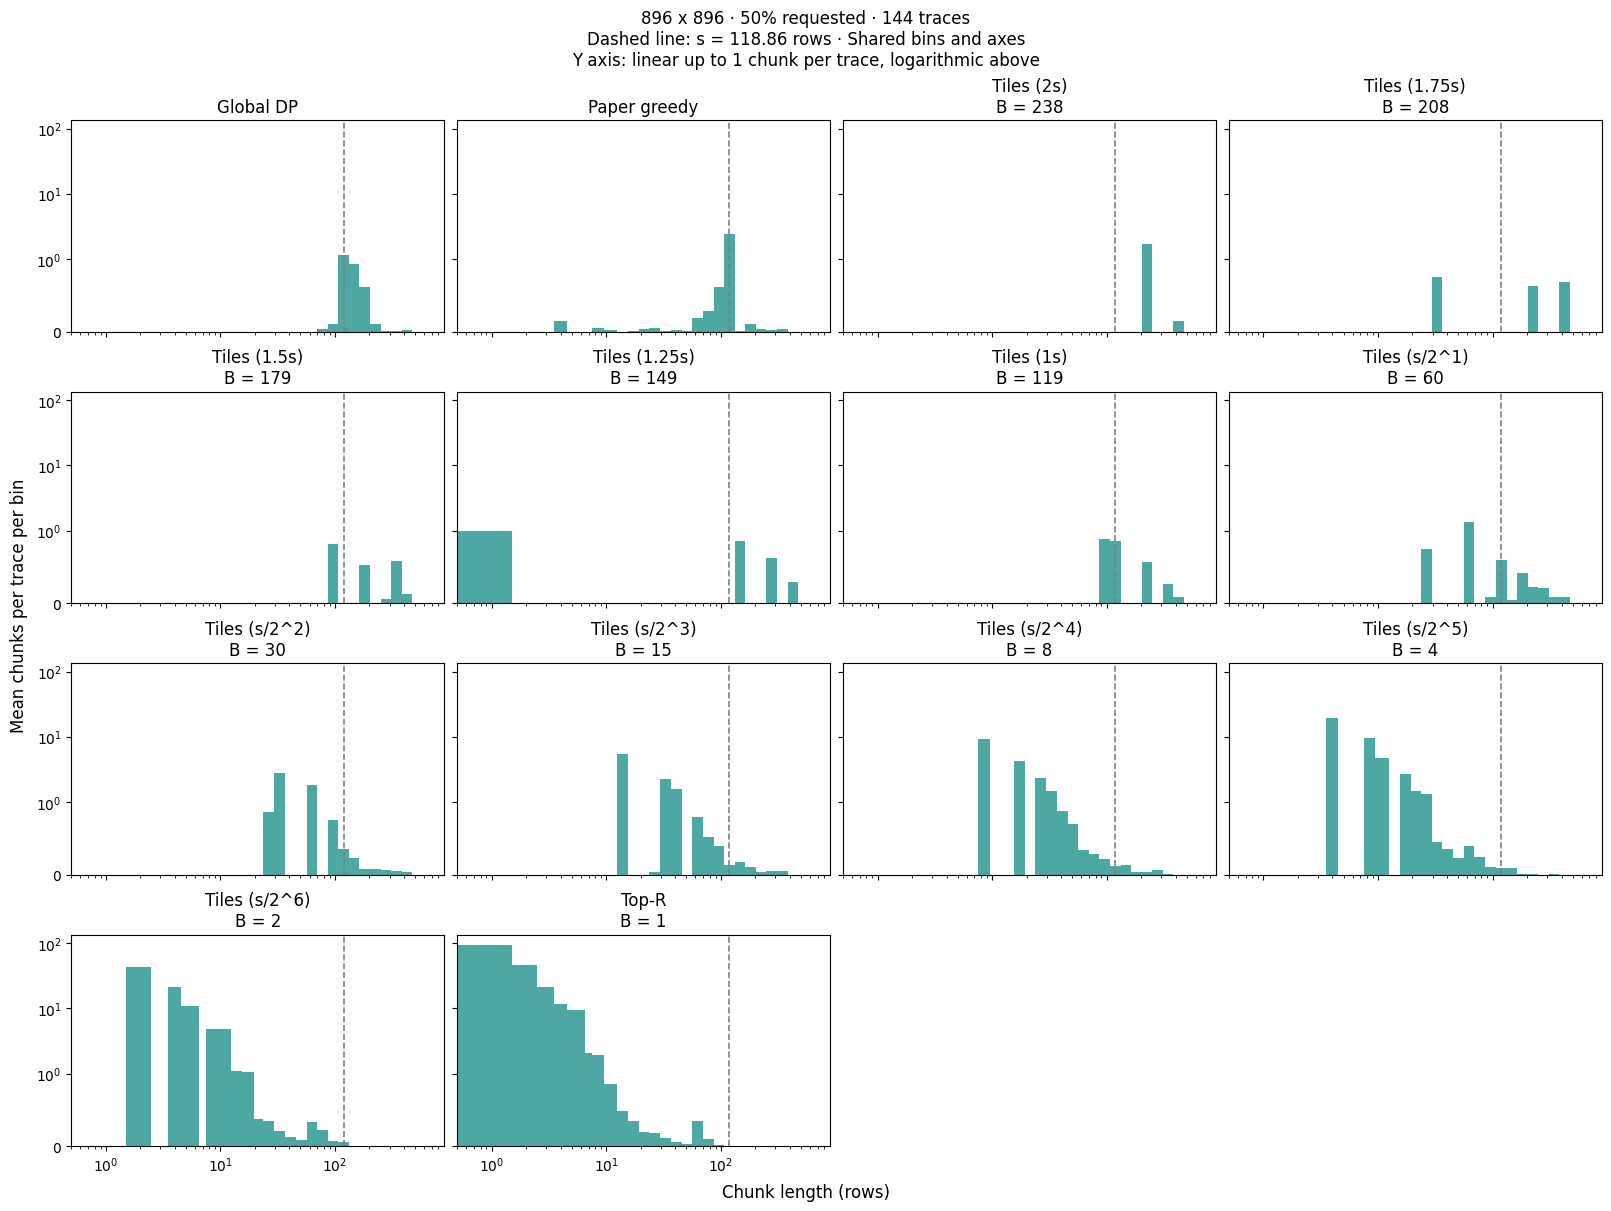

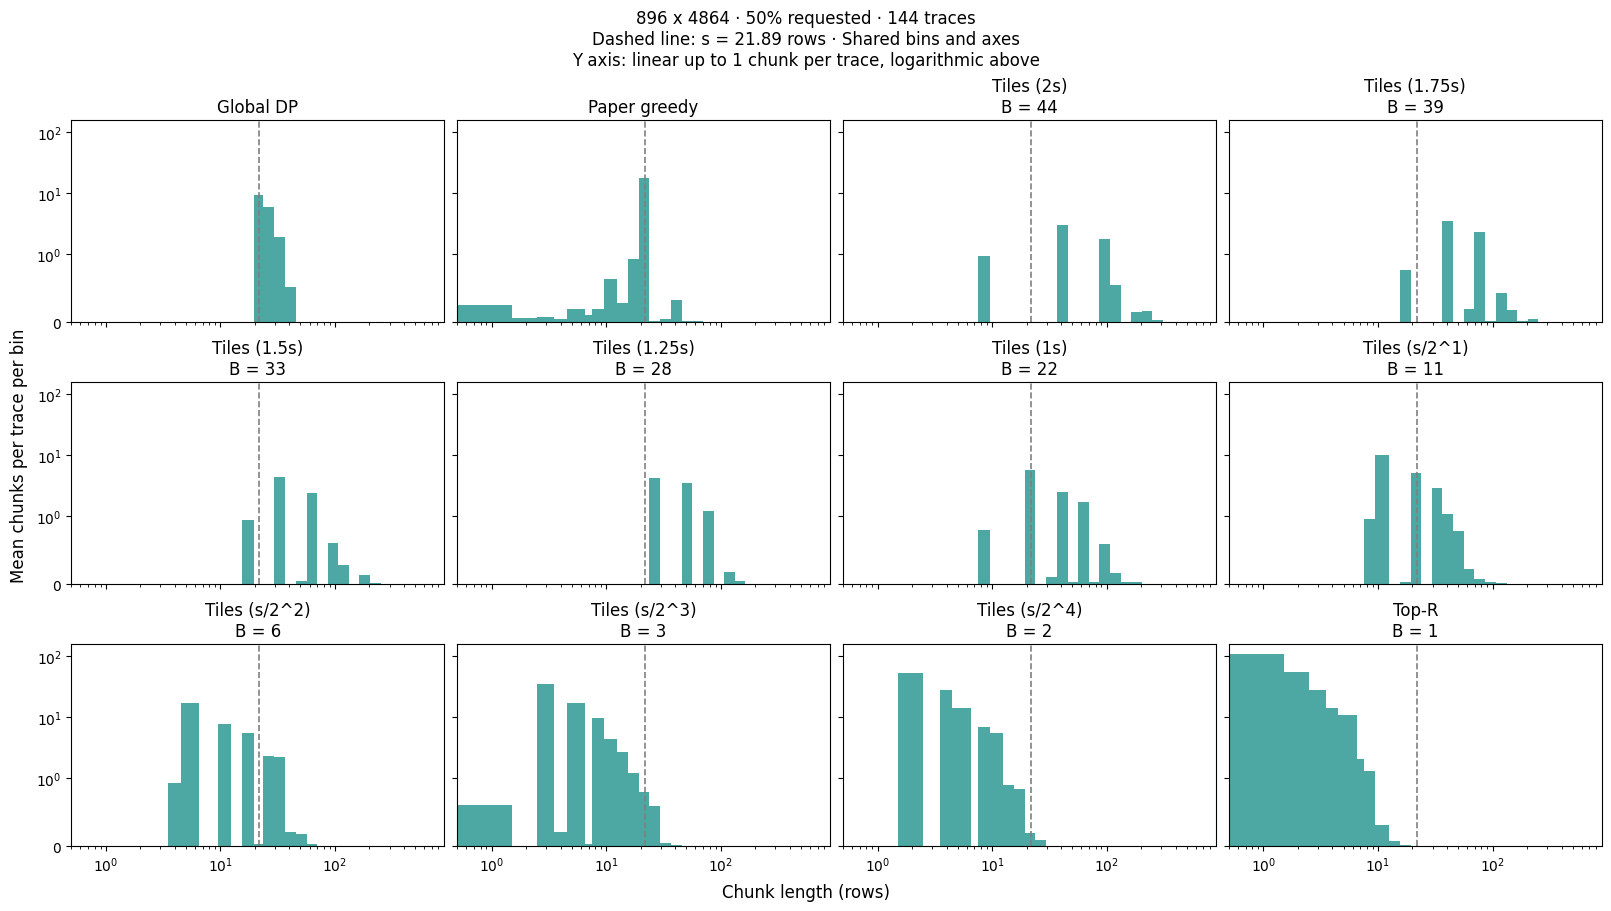

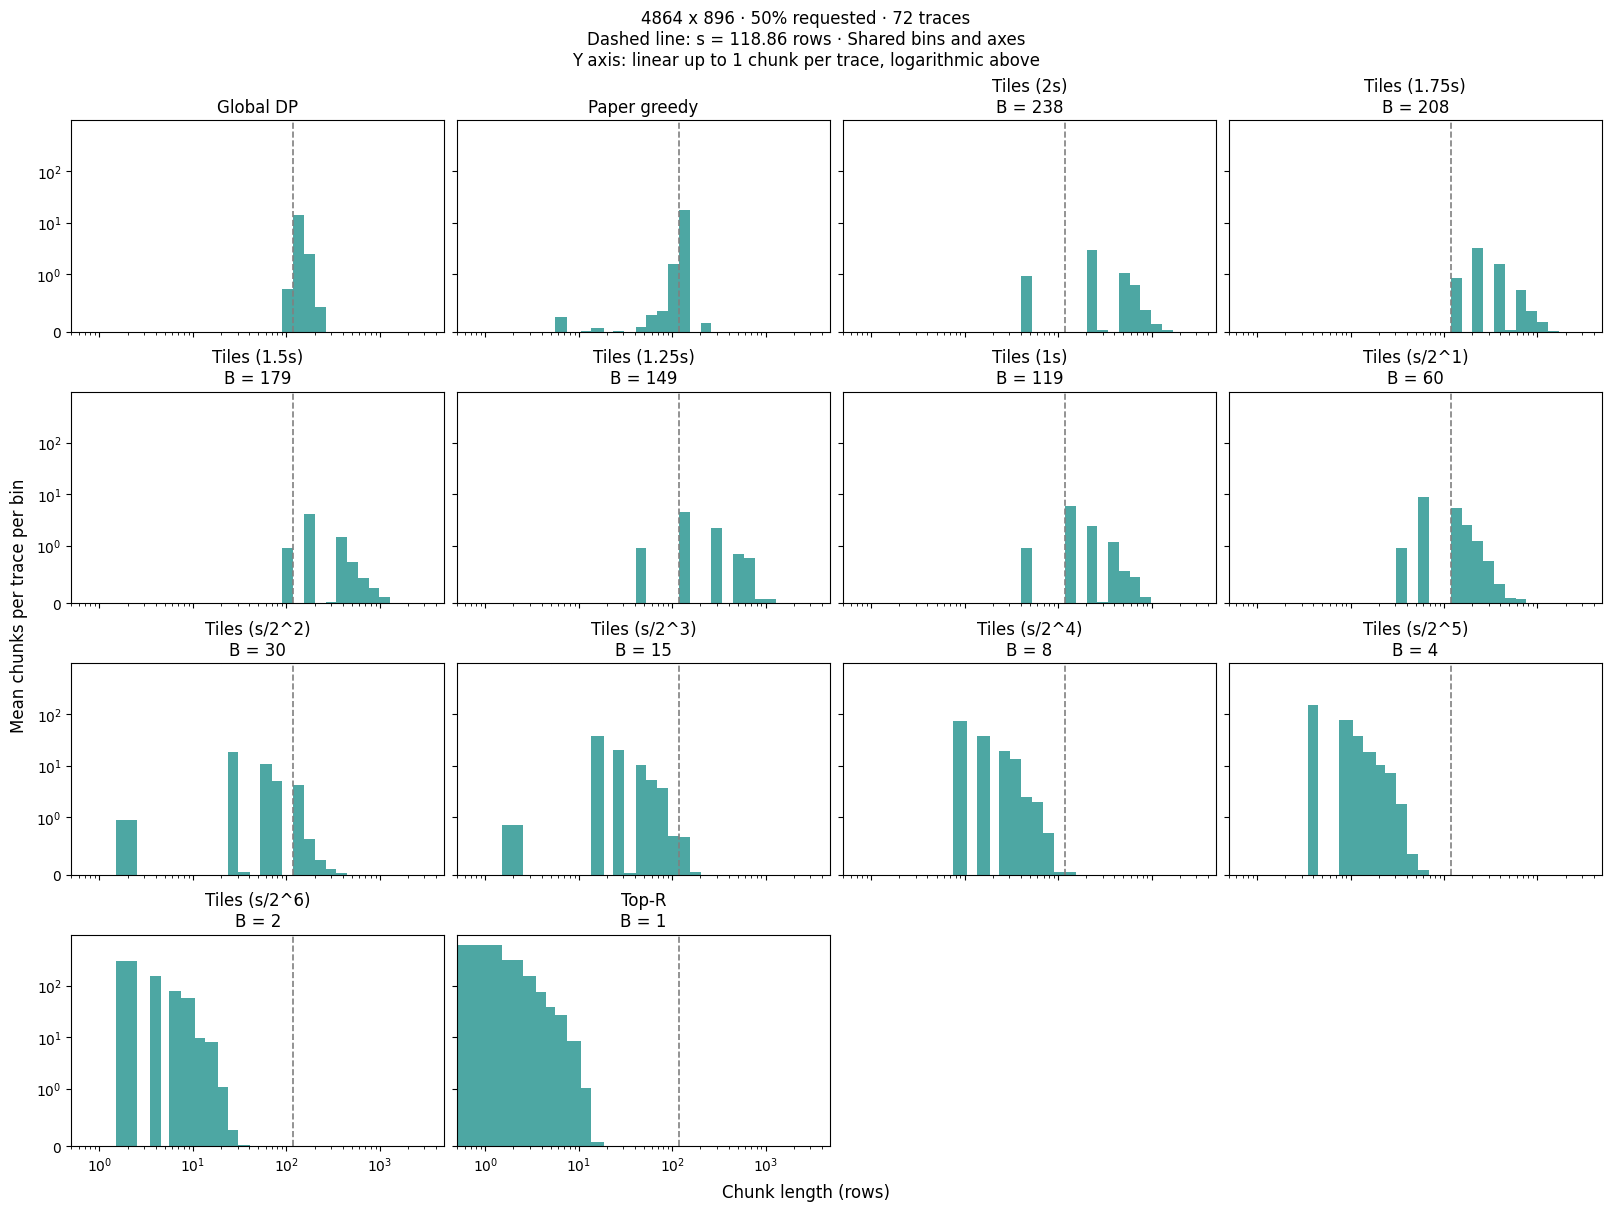

In [15]:
for result in chunks.values():
    fig = draw_shape(result, FRACTION)

    plt.show()
    plt.close(fig)